# Daily One-Day-Ahead Wind Speed Forecasting — NWTC M2

Replikasi ringan Altork (2025) pada data bulanan, lalu ekstensi utama: peramalan
kecepatan angin harian satu hari ke depan (t+1) di NREL/NLR National Wind
Technology Center M2, Boulder, Colorado (2019–2023).

Sumber data: MIDC `https://midcdmz.nlr.gov/apps/data_api.pl?site=NWTC`.
Dataset diproduksi oleh `scripts/download_data.py`; notebook ini tidak mengunduh data.


## 1. Setup

Konfigurasi path, seed, dan import untuk seluruh notebook. Import baru untuk section berikutnya ditambahkan di sini agar notebook tetap bisa dieksekusi dari atas ke bawah.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

DATA_DIR = Path("data/processed")
FIG_DIR = Path("results/figures")
RESULTS_DIR = Path("results")
RANDOM_STATE = 42

FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Data Loading and Quality

`daily.csv` dan `monthly.csv` dihasilkan `scripts/download_data.py` dari export 1 menit MIDC. Assertion di bawah mengunci bentuk dataset.

In [2]:
daily = pd.read_csv(DATA_DIR / "daily.csv", parse_dates=["date"], index_col="date")
monthly = pd.read_csv(DATA_DIR / "monthly.csv", index_col="month")
monthly.index = pd.PeriodIndex(monthly.index, freq="M")
quality = pd.read_csv(DATA_DIR / "data_quality.csv")

assert len(daily) == 1826
assert len(monthly) == 60
assert len(quality) == 60
assert daily.index.min() == pd.Timestamp("2019-01-01")
assert daily.index.max() == pd.Timestamp("2023-12-31")
assert monthly.index.min() == pd.Period("2019-01", "M")
assert monthly.index.max() == pd.Period("2023-12", "M")
assert not daily.index.duplicated().any()

display(daily.head())
display(monthly.head())
display(quality.head())

,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
date,,,,,,,,,,
2019-01-01,1.456649,137.900011,0.670426,-0.741976,-14.284154,71.617563,812.663540,0.000,1440,1.0
2019-01-02,2.470028,250.340149,-0.941707,-0.336435,-1.061922,42.507257,811.720479,2.540,1440,1.0
2019-01-03,2.955379,261.396810,-0.988748,-0.149590,6.567799,31.810069,811.304703,0.762,1440,1.0
2019-01-04,3.437153,292.760810,-0.922128,0.386885,11.113537,25.410889,811.827401,0.000,1440,1.0
2019-01-05,2.498463,328.467488,-0.522982,0.852344,10.110012,26.780938,811.307790,0.000,1440,1.0


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
month,,,,,,,,,,
2019-01,4.901771,285.218506,-0.964932,0.262501,2.244921,45.962357,811.964664,33.022,44640,1.0
2019-02,4.350938,329.941189,-0.500889,0.865512,-1.525074,53.232528,806.386784,7.620,40320,1.0
2019-03,3.419137,352.690688,-0.127226,0.991874,1.562742,57.794549,812.846325,54.618,44640,1.0
2019-04,4.076535,340.259863,-0.337755,0.941234,8.584396,54.393300,810.724961,30.222,43200,1.0
2019-05,3.519509,340.867599,-0.327752,0.944764,9.483338,63.261168,810.783454,97.546,44640,1.0


,year,month,expected_minutes,n_rows,n_missing_minutes,n_duplicate_minutes,valid_wind_speed,valid_wind_dir,valid_temperature,valid_humidity,valid_pressure,valid_precipitation
0,2019,1,44640,44640,0,0,44640,44640,44640,44640,44640,44640
1,2019,2,40320,40320,0,0,40320,40320,40320,40320,40320,40320
2,2019,3,44640,44640,0,0,44640,44640,44640,44640,44640,44640
3,2019,4,43200,43200,0,0,43200,43200,43200,43200,43200,43200
4,2019,5,44640,44640,0,0,44640,44640,44640,44640,44640,44640


In [3]:
missing_daily = daily.isna().sum().to_frame("missing_days")
missing_daily["missing_pct"] = (missing_daily["missing_days"] / len(daily) * 100).round(2)

print(f"daily: {len(daily)} hari, {daily.index.min().date()} -> {daily.index.max().date()}")
print(f"monthly: {len(monthly)} bulan, {monthly.index.min()} -> {monthly.index.max()}")
display(missing_daily.T)
display(monthly.isna().sum().to_frame("missing_months").T)

daily: 1826 hari, 2019-01-01 -> 2023-12-31
monthly: 60 bulan, 2019-01 -> 2023-12


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
missing_days,0.0,0.0,0.0,0.0,19.00,2.00,0.0,0.0,0.0,0.0
missing_pct,0.0,0.0,0.0,0.0,1.04,0.11,0.0,0.0,0.0,0.0


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
missing_months,0,0,0,0,0,0,0,0,0,0


Coverage per bulan: `valid_wind_speed / expected_minutes` dari `data_quality.csv`.

In [4]:
coverage = quality.assign(valid_fraction=quality["valid_wind_speed"] / quality["expected_minutes"])
display(coverage.nsmallest(5, "valid_fraction")[["year", "month", "n_rows", "n_duplicate_minutes", "valid_fraction"]])
print("bulan dengan menit duplikat di sumber:", int((coverage["n_duplicate_minutes"] > 0).sum()))

,year,month,n_rows,n_duplicate_minutes,valid_fraction
7,2019,8,44580,60,0.998656
28,2021,5,44625,0,0.999664
30,2021,7,44640,0,0.999754
50,2023,3,44631,0,0.999798
0,2019,1,44640,0,1.000000


bulan dengan menit duplikat di sumber: 2


## 3. Exploratory Data Analysis

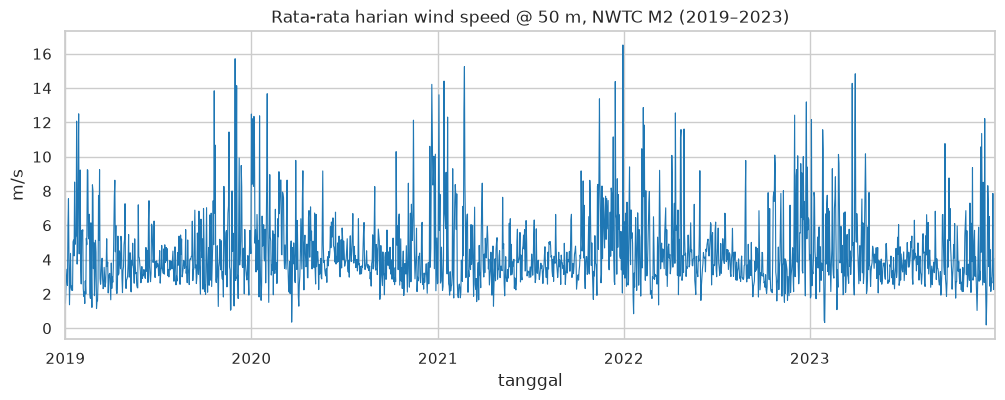

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
daily["wind_speed_50m"].plot(ax=ax, linewidth=0.8, color="tab:blue")
ax.set_title("Rata-rata harian wind speed @ 50 m, NWTC M2 (2019–2023)")
ax.set_xlabel("tanggal")
ax.set_ylabel("m/s")
fig.savefig(FIG_DIR / "fig_daily_wind_speed.png", dpi=150, bbox_inches="tight")
plt.show()

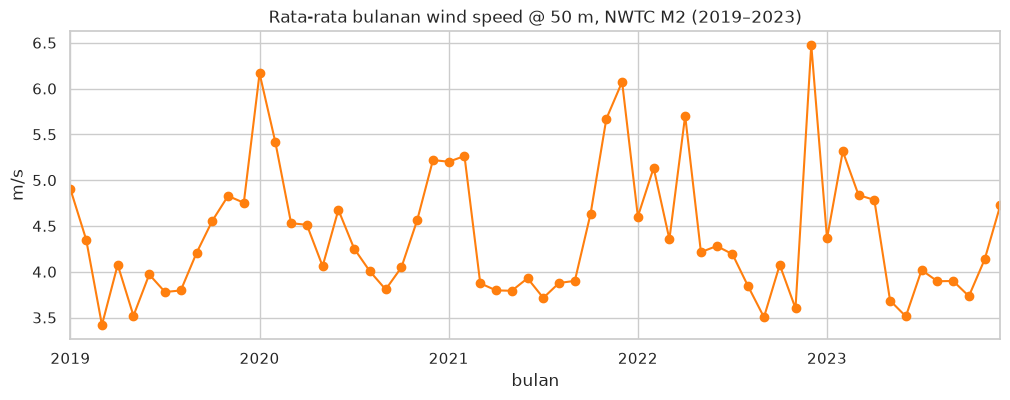

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
daily["wind_speed_50m"].resample("MS").mean().plot(ax=ax, marker="o", color="tab:orange")
ax.set_title("Rata-rata bulanan wind speed @ 50 m, NWTC M2 (2019–2023)")
ax.set_xlabel("bulan")
ax.set_ylabel("m/s")
fig.savefig(FIG_DIR / "fig_monthly_wind_speed.png", dpi=150, bbox_inches="tight")
plt.show()

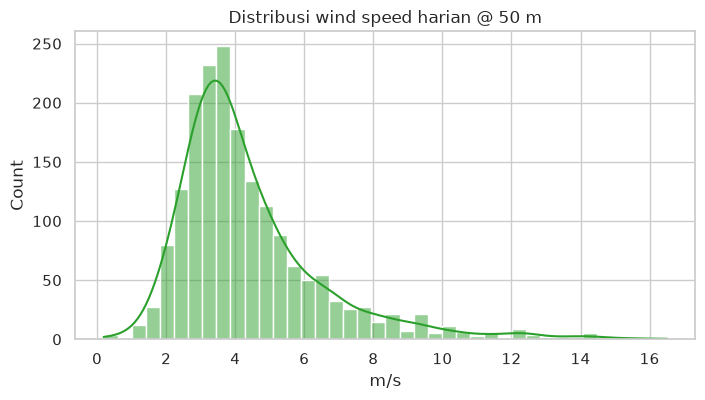

count    1826.000000
mean        4.396697
std         2.141774
min         0.189000
25%         3.044868
50%         3.821707
75%         5.116961
max        16.510985
Name: wind_speed_50m, dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(daily["wind_speed_50m"].dropna(), bins=40, kde=True, ax=ax, color="tab:green")
ax.set_title("Distribusi wind speed harian @ 50 m")
ax.set_xlabel("m/s")
fig.savefig(FIG_DIR / "fig_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

daily["wind_speed_50m"].describe()

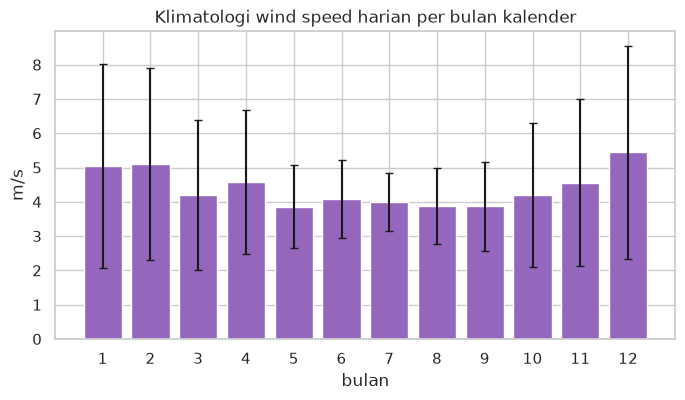

,mean,std,count
date,,,
1,5.047,2.979,155
2,5.098,2.806,141
3,4.203,2.180,155
4,4.575,2.106,150
5,3.855,1.210,155
6,4.074,1.140,150
7,3.992,0.835,155
8,3.883,1.115,155
9,3.863,1.307,150


In [8]:
climatology = daily.groupby(daily.index.month)["wind_speed_50m"].agg(["mean", "std", "count"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(climatology.index, climatology["mean"], yerr=climatology["std"], capsize=3, color="tab:purple")
ax.set_xticks(range(1, 13))
ax.set_xlabel("bulan")
ax.set_ylabel("m/s")
ax.set_title("Klimatologi wind speed harian per bulan kalender")
fig.savefig(FIG_DIR / "fig_monthly_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

climatology.round(3)

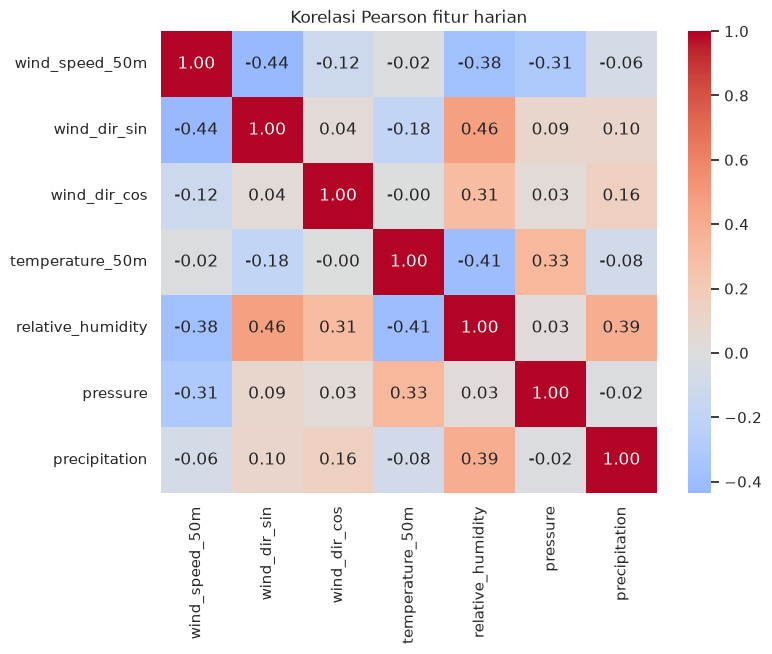

,pearson_r
wind_speed_50m,1.000
temperature_50m,-0.018
precipitation,-0.065
wind_dir_cos,-0.122
pressure,-0.306
relative_humidity,-0.381
wind_dir_sin,-0.436


In [9]:
CORR_COLS = [
    "wind_speed_50m", "wind_dir_sin", "wind_dir_cos", "temperature_50m",
    "relative_humidity", "pressure", "precipitation",
]
corr = daily[CORR_COLS].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelasi Pearson fitur harian")
fig.savefig(FIG_DIR / "fig_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr["wind_speed_50m"].sort_values(ascending=False).to_frame("pearson_r").round(3)

## 4. Monthly Sanity Check (Replication)

Replikasi ringan Altork (2025): 60 observasi bulanan, lima input seperti paper,
split acak 70/15/15 dengan `random_state=42`. Split acak **disengaja** di sini
untuk meniru paper; eksperimen utama di section 5 memakai split kronologis.

Angka paper tidak harus identik karena paper tidak merinci hyperparameter,
split, dan detail agregasi.

### 4.1 Dataset dan split

In [10]:
sanity_features = ["pressure", "temperature_50m", "wind_dir_deg", "relative_humidity", "precipitation"]
sanity_target = "wind_speed_50m"

sanity = monthly.dropna(subset=sanity_features + [sanity_target]).copy()
print("sanity observations:", len(sanity))

X = sanity[sanity_features]
y = sanity[sanity_target]

# 70/15/15 seperti paper: 60 observasi -> 42 train / 9 validation / 9 test.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=len(X_test) / len(X_trainval), random_state=RANDOM_STATE
)
print("train/val/test:", len(X_train), len(X_val), len(X_test))


sanity observations: 60
train/val/test: 42 9 9


### 4.2 Model

Scaler hanya di-fit pada train lewat pipeline; model final di-refit pada train+validation dengan pipeline baru.

In [11]:
def sanity_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mse)),
        "MSE": float(mse),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


sanity_trainval = (pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
sanity_results_rows = []

def sanity_fit_and_evaluate(name, estimator, param_grid=None):
    if param_grid is None:
        search = estimator
    else:
        search = GridSearchCV(
            estimator,
            param_grid,
            cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
    search.fit(X_train, y_train)
    fitted = search.best_estimator_ if param_grid is not None else search
    val_metrics = sanity_metrics(y_val, fitted.predict(X_val))

    final = clone(fitted).fit(*sanity_trainval)
    test_metrics = sanity_metrics(y_test, final.predict(X_test))
    sanity_results_rows.append({"model": name, **test_metrics})
    print(f"{name}: validation RMSE {val_metrics['RMSE']:.4f} | test RMSE {test_metrics['RMSE']:.4f}")
    return final


sanity_final_models = {
    "Linear Regression": sanity_fit_and_evaluate(
        "Linear Regression", make_pipeline(MinMaxScaler(feature_range=(-1, 1)), LinearRegression())
    ),
    "SVR": sanity_fit_and_evaluate(
        "SVR",
        make_pipeline(MinMaxScaler(feature_range=(-1, 1)), SVR(kernel="rbf")),
        {"svr__C": [1, 10, 100], "svr__gamma": ["scale", 0.1], "svr__epsilon": [0.01, 0.1]},
    ),
    "Fine Tree": sanity_fit_and_evaluate(
        "Fine Tree",
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [None, 3, 5, 10], "min_samples_leaf": [1, 2, 4]},
    ),
}

Linear Regression: validation RMSE 0.4708 | test RMSE 0.4923


SVR: validation RMSE 0.4389 | test RMSE 0.5372
Fine Tree: validation RMSE 0.5008 | test RMSE 0.5156


### 4.3 Pelaporan

In [12]:
sanity_results = pd.DataFrame(sanity_results_rows).sort_values("RMSE").reset_index(drop=True)

paper_reference = pd.DataFrame([
    {"model": "Linear Regression", "paper_RMSE": 0.29555, "paper_MSE": 0.087352, "paper_MAE": 0.18061, "paper_R2": 0.97},
    {"model": "SVR", "paper_RMSE": 0.32275, "paper_MSE": np.nan, "paper_MAE": np.nan, "paper_R2": 0.96},
    {"model": "Fine Tree", "paper_RMSE": 0.44042, "paper_MSE": np.nan, "paper_MAE": np.nan, "paper_R2": 0.93},
])

display(sanity_results.round(4))
display(paper_reference)

assert np.isfinite(sanity_results[["RMSE", "MSE", "MAE", "R2"]].to_numpy()).all()
lr_r2 = sanity_results.loc[sanity_results["model"] == "Linear Regression", "R2"].iloc[0]
# Batas atas menangkap leakage (R2 ~ 1). Batas bawah hanya menuntut model lebih baik
# dari rata-rata: pada 9 observasi test, R2 terlalu tidak stabil untuk ambang lebih ketat.
assert 0.0 < lr_r2 < 0.999, f"R2 Linear Regression di luar rentang wajar: {lr_r2}"
print(f"catatan: test hanya {len(y_test)} observasi bulanan; R2 tidak stabil pada n={len(y_test)}")
print(f"standar deviasi target test: {y_test.std():.4f} m/s")

sanity_results.to_csv(RESULTS_DIR / "sanity_check_metrics.csv", index=False)
print("tersimpan:", RESULTS_DIR / "sanity_check_metrics.csv")


,model,RMSE,MSE,MAE,R2
0,Linear Regression,0.4923,0.2424,0.3380,0.4819
1,Fine Tree,0.5156,0.2658,0.4189,0.4318
2,SVR,0.5372,0.2886,0.3754,0.3831


,model,paper_RMSE,paper_MSE,paper_MAE,paper_R2
0,Linear Regression,0.29555,0.087352,0.18061,0.97
1,SVR,0.32275,NaN,NaN,0.96
2,Fine Tree,0.44042,NaN,NaN,0.93


catatan: test hanya 9 observasi bulanan; R2 tidak stabil pada n=9
standar deviasi target test: 0.7255 m/s
tersimpan: results/sanity_check_metrics.csv


## 5. t+1 Dataset and Linear Baseline

Forecast diterbitkan akhir hari t (23:59) untuk target rata-rata wind speed hari t+1.
Konsekuensi keras:

- fitur meteorologi memakai nilai hari t (dan lag sebelumnya), tidak pernah hari t+1;
- target adalah `wind_speed_50m(t+1)`;
- fitur kalender memakai day-of-year hari target (t+1), karena tanggal target sudah diketahui saat forecast terbit;
- split kronologis berdasarkan `target_date`, tanpa shuffling.

### 5.1 Feature set (16 fitur)

In [13]:
FEATURES = [
    "wind_speed_lag0", "wind_speed_lag1", "wind_speed_lag2", "wind_speed_lag3",
    "wind_speed_lag4", "wind_speed_lag5", "wind_speed_lag6", "wind_speed_lag7",
    "wind_dir_sin", "wind_dir_cos", "temperature_50m", "pressure",
    "relative_humidity", "precipitation", "doy_sin", "doy_cos",
]
len(FEATURES)

16

### 5.2 Interpolasi gap fitur pendek, lalu pembentukan dataset supervised

Interpolasi hanya untuk fitur non-wind-speed, maksimal 2 hari, hanya di dalam gap. Target dan `wind_speed_50m` tidak pernah diinterpolasi.

In [14]:
FEATURE_COLS_TO_INTERPOLATE = [
    "wind_dir_sin", "wind_dir_cos", "temperature_50m",
    "relative_humidity", "pressure", "precipitation",
]
missing_before = daily[FEATURE_COLS_TO_INTERPOLATE].isna().sum()
daily[FEATURE_COLS_TO_INTERPOLATE] = daily[FEATURE_COLS_TO_INTERPOLATE].interpolate(
    method="linear", limit=2, limit_area="inside"
)
missing_after = daily[FEATURE_COLS_TO_INTERPOLATE].isna().sum()
display(pd.DataFrame({"before": missing_before, "after": missing_after}))

sup = daily.sort_index().copy()
for lag in range(8):
    sup[f"wind_speed_lag{lag}"] = sup["wind_speed_50m"].shift(lag)
sup["target"] = sup["wind_speed_50m"].shift(-1)
sup["target_date"] = sup.index + pd.Timedelta(days=1)
doy = sup["target_date"].dt.day_of_year
sup["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
sup["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
sup = sup.dropna(subset=FEATURES + ["target"]).copy()
print("supervised rows after drop:", len(sup), "of", len(daily))


,before,after
wind_dir_sin,0,0
wind_dir_cos,0,0
temperature_50m,19,10
relative_humidity,2,0
pressure,0,0
precipitation,0,0


supervised rows after drop: 1808 of 1826


### 5.3 Audit leakage

In [15]:
assert (sup["target_date"] == sup.index + pd.Timedelta(days=1)).all()
assert np.allclose(
    sup["target"].to_numpy(),
    daily.reindex(sup["target_date"])["wind_speed_50m"].to_numpy(),
)
assert np.allclose(
    sup["wind_speed_lag0"].to_numpy(),
    daily.reindex(sup.index)["wind_speed_50m"].to_numpy(),
)
assert set(FEATURES).isdisjoint({"target", "target_date"})
print("leakage audit passed: target = wind_speed(t+1), lag0 = wind_speed(t), tidak ada fitur hari t+1")

leakage audit passed: target = wind_speed(t+1), lag0 = wind_speed(t), tidak ada fitur hari t+1


### 5.4 Split kronologis berdasarkan tanggal target

In [16]:
train = sup[sup["target_date"] <= pd.Timestamp("2021-12-31")]
val = sup[(sup["target_date"] >= pd.Timestamp("2022-01-01")) & (sup["target_date"] <= pd.Timestamp("2022-12-31"))]
test = sup[sup["target_date"] >= pd.Timestamp("2023-01-01")]

assert len(train) + len(val) + len(test) == len(sup)
assert train["target_date"].max() < val["target_date"].min()
assert val["target_date"].max() < test["target_date"].min()

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name}: {len(part)} baris | target_date {part['target_date'].min().date()} -> {part['target_date'].max().date()}")

train: 1078 baris | target_date 2019-01-09 -> 2021-12-31
validation: 365 baris | target_date 2022-01-01 -> 2022-12-31
test: 365 baris | target_date 2023-01-01 -> 2023-12-31


### 5.5 Metrik dan akumulator hasil

In [17]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mse)),
        "MSE": float(mse),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


results = []

def add_result(model_name, y_true, y_pred):
    row = {"model": model_name, **regression_metrics(y_true, y_pred)}
    results.append(row)
    return row

### 5.6 Baseline persistence

In [18]:
add_result("Persistence", test["target"], test["wind_speed_lag0"])
persistence_rmse = results[0]["RMSE"]
persistence_mae = results[0]["MAE"]
print(f"persistence test RMSE {persistence_rmse:.4f} | MAE {persistence_mae:.4f}")

persistence test RMSE 2.6282 | MAE 1.8013


### 5.7 Linear Regression

In [19]:
lr_scaler = MinMaxScaler(feature_range=(-1, 1))
X_train_scaled = lr_scaler.fit_transform(train[FEATURES])

assert np.allclose(lr_scaler.data_min_, train[FEATURES].min().to_numpy())
assert np.allclose(lr_scaler.data_max_, train[FEATURES].max().to_numpy())

lr_train_scaled = LinearRegression().fit(X_train_scaled, train["target"])
lr_val_rmse = float(np.sqrt(mean_squared_error(val["target"], lr_train_scaled.predict(lr_scaler.transform(val[FEATURES])))))
print(f"Linear Regression validation RMSE (scaler train-only): {lr_val_rmse:.4f}")

lr_final = make_pipeline(MinMaxScaler(feature_range=(-1, 1)), LinearRegression())
trainval = pd.concat([train, val])
lr_final.fit(trainval[FEATURES], trainval["target"])

add_result("Linear Regression", test["target"], lr_final.predict(test[FEATURES]))
final_models = {"Linear Regression": lr_final}

Linear Regression validation RMSE (scaler train-only): 2.0145


### 5.8 Tabel metrik test

In [20]:
metrics_df = pd.DataFrame(results)
metrics_df["RMSE_reduction_pct"] = 100 * (persistence_rmse - metrics_df["RMSE"]) / persistence_rmse
metrics_df["MAE_reduction_pct"] = 100 * (persistence_mae - metrics_df["MAE"]) / persistence_mae
metrics_df = metrics_df.sort_values("RMSE").reset_index(drop=True)
metrics_df.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)

assert abs(metrics_df.loc[metrics_df["model"] == "Persistence", "RMSE_reduction_pct"].iloc[0]) < 1e-9
metrics_df.round(4)

,model,RMSE,MSE,MAE,R2,RMSE_reduction_pct,MAE_reduction_pct
0,Linear Regression,2.0271,4.1092,1.4401,0.0616,22.8702,20.0523
1,Persistence,2.6282,6.9074,1.8013,-0.5774,0.0000,0.0000


## 6. Nonlinear Models and Tuning

Tuning memakai `TimeSeriesSplit(n_splits=3)` **di dalam train** (tanpa shuffling).
Konfigurasi terbaik dievaluasi pada validation, lalu model final di-refit pada
train+validation dengan pipeline baru (scaler di-fit ulang, bukan memakai scaler train).

### 6.1 Persiapan bersama

In [21]:
tscv = TimeSeriesSplit(n_splits=3)
X_train, y_train = train[FEATURES], train["target"]
X_val, y_val = val[FEATURES], val["target"]
X_test, y_test = test[FEATURES], test["target"]
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])
print("train/val/test:", len(X_train), len(X_val), len(X_test))

train/val/test: 1078 365 365


### 6.2 SVR (RBF)

In [22]:
svr_pipe = make_pipeline(MinMaxScaler(feature_range=(-1, 1)), SVR(kernel="rbf"))
svr_grid = {
    "svr__C": [0.1, 1, 10, 100],
    "svr__gamma": ["scale", 0.01, 0.1],
    "svr__epsilon": [0.01, 0.1, 0.5],
}
svr_search = GridSearchCV(svr_pipe, svr_grid, cv=tscv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
svr_search.fit(X_train, y_train)
print("SVR best:", svr_search.best_params_, "| CV RMSE", round(-svr_search.best_score_, 4))

SVR best: {'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale'} | CV RMSE 2.2171


### 6.3 Fine Tree

In [23]:
tree_grid = {"max_depth": [None, 5, 10, 20], "min_samples_leaf": [1, 2, 4, 8]}
tree_search = GridSearchCV(DecisionTreeRegressor(random_state=RANDOM_STATE), tree_grid, cv=tscv,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
tree_search.fit(X_train, y_train)
print("Fine Tree best:", tree_search.best_params_, "| CV RMSE", round(-tree_search.best_score_, 4))

Fine Tree best: {'max_depth': 5, 'min_samples_leaf': 8} | CV RMSE 2.3891


### 6.4 Random Forest

`n_jobs=1` pada `GridSearchCV` karena estimator RF sudah paralel; menghindari oversubscription.

In [24]:
rf_grid = {
    "n_estimators": [300],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 1.0],
}
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    rf_grid, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=1,
)
rf_search.fit(X_train, y_train)
print("Random Forest best:", rf_search.best_params_, "| CV RMSE", round(-rf_search.best_score_, 4))

Random Forest best: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 300} | CV RMSE 2.1155


### 6.5 Validation, refit train+validation, evaluasi test

In [25]:
def evaluate_search(name, search):
    val_rmse = float(np.sqrt(mean_squared_error(y_val, search.best_estimator_.predict(X_val))))
    final = clone(search.best_estimator_).fit(X_trainval, y_trainval)
    add_result(name, y_test, final.predict(X_test))
    print(f"{name}: validation RMSE {val_rmse:.4f}")
    return final, val_rmse


svr_final, svr_val_rmse = evaluate_search("SVR", svr_search)
tree_final, tree_val_rmse = evaluate_search("Fine Tree", tree_search)
rf_final, rf_val_rmse = evaluate_search("Random Forest", rf_search)

final_models.update({"SVR": svr_final, "Fine Tree": tree_final, "Random Forest": rf_final})
sorted(final_models)

SVR: validation RMSE 2.0187
Fine Tree: validation RMSE 2.0325


Random Forest: validation RMSE 1.9749


['Fine Tree', 'Linear Regression', 'Random Forest', 'SVR']

### 6.6 Hyperparameter final dan tabel metrik

In [26]:
best = {
    "SVR": {"params": svr_search.best_params_, "val_rmse": svr_val_rmse},
    "Fine Tree": {"params": tree_search.best_params_, "val_rmse": tree_val_rmse},
    "Random Forest": {"params": rf_search.best_params_, "val_rmse": rf_val_rmse},
}
with open(RESULTS_DIR / "best_params.json", "w") as f:
    json.dump(best, f, indent=2, default=str)
print(json.dumps(best, indent=2, default=str))

{
  "SVR": {
    "params": {
      "svr__C": 1,
      "svr__epsilon": 0.01,
      "svr__gamma": "scale"
    },
    "val_rmse": 2.018653675755969
  },
  "Fine Tree": {
    "params": {
      "max_depth": 5,
      "min_samples_leaf": 8
    },
    "val_rmse": 2.032548887802719
  },
  "Random Forest": {
    "params": {
      "max_depth": 20,
      "max_features": "sqrt",
      "min_samples_leaf": 4,
      "n_estimators": 300
    },
    "val_rmse": 1.9748501685540825
  }
}


In [27]:
metrics_df = pd.DataFrame(results)
metrics_df["RMSE_reduction_pct"] = 100 * (persistence_rmse - metrics_df["RMSE"]) / persistence_rmse
metrics_df["MAE_reduction_pct"] = 100 * (persistence_mae - metrics_df["MAE"]) / persistence_mae
metrics_df = metrics_df.sort_values("RMSE").reset_index(drop=True)
metrics_df.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)

assert np.isfinite(metrics_df[["RMSE", "MSE", "MAE", "R2"]].to_numpy()).all()
assert metrics_df.loc[metrics_df["model"] == "Random Forest", "RMSE"].iloc[0] < 100
metrics_df.round(4)

,model,RMSE,MSE,MAE,R2,RMSE_reduction_pct,MAE_reduction_pct
0,SVR,2.0044,4.0177,1.3525,0.0825,23.7341,24.9168
1,Random Forest,2.0045,4.0180,1.4171,0.0824,23.7311,21.3300
2,Linear Regression,2.0271,4.1092,1.4401,0.0616,22.8702,20.0523
3,Fine Tree,2.1515,4.6288,1.5357,-0.0570,18.1394,14.7465
4,Persistence,2.6282,6.9074,1.8013,-0.5774,0.0000,0.0000


## 7. Feature Importance and Error Analysis

Model ML terbaik dipilih dari RMSE terendah pada test, **tanpa** mengikutkan
persistence sebagai kandidat; jika persistence yang terendah, hal itu dilaporkan
apa adanya. Koefisien Linear Regression hanya bermakna setelah scaling
(Min-Max ke [-1, 1] di-fit pada train+validation).

### 7.1 Feature importance

best ML model: SVR


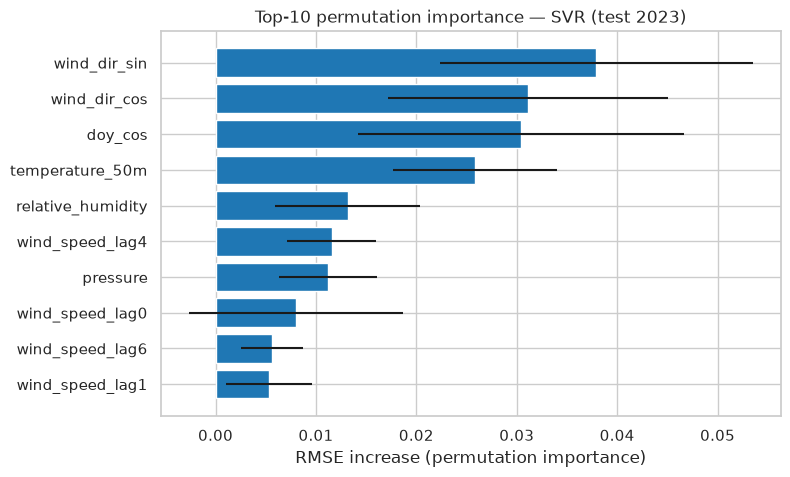

,feature,rf_impurity,permutation_mean,permutation_std,lr_coef
0,wind_dir_sin,0.0644,0.0379,0.0156,-0.2162
1,wind_dir_cos,0.0684,0.0311,0.0139,-0.2514
2,doy_cos,0.1043,0.0304,0.0162,0.5512
3,temperature_50m,0.0613,0.0258,0.0082,0.3815
4,relative_humidity,0.0881,0.0132,0.0072,-0.2292
5,wind_speed_lag4,0.0482,0.0116,0.0044,-0.0050
6,pressure,0.0861,0.0112,0.0049,-1.0338
7,wind_speed_lag0,0.1283,0.0080,0.0106,1.6058
8,wind_speed_lag6,0.0435,0.0057,0.0031,-0.1237
9,wind_speed_lag1,0.0548,0.0053,0.0042,-0.1556


In [28]:
ml_metrics = metrics_df[metrics_df["model"] != "Persistence"].reset_index(drop=True)
best_model_name = ml_metrics.loc[0, "model"]
best_ml_model = final_models[best_model_name]
print("best ML model:", best_model_name)

rf_model = final_models["Random Forest"]
perm = permutation_importance(
    best_ml_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)

importance = pd.DataFrame({
    "feature": FEATURES,
    "rf_impurity": rf_model.feature_importances_,
    "permutation_mean": perm.importances_mean,
    "permutation_std": perm.importances_std,
    "lr_coef": final_models["Linear Regression"].named_steps["linearregression"].coef_,
}).sort_values("permutation_mean", ascending=False).reset_index(drop=True)
importance.to_csv(RESULTS_DIR / "feature_importance.csv", index=False)

top_importance = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_importance["feature"], top_importance["permutation_mean"],
        xerr=top_importance["permutation_std"], color="tab:blue")
ax.set_xlabel("RMSE increase (permutation importance)")
ax.set_title(f"Top-10 permutation importance — {best_model_name} (test 2023)")
fig.savefig(FIG_DIR / "fig_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.round(4)

### 7.2 Error per musim

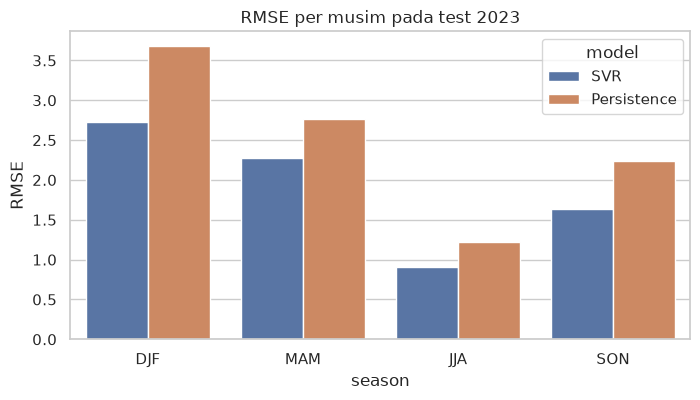

,season,model,RMSE,MAE,n
0,DJF,SVR,2.7292,2.1661,90
1,MAM,SVR,2.2762,1.4382,92
2,JJA,SVR,0.9051,0.6693,92
3,SON,SVR,1.6378,1.1519,91
4,DJF,Persistence,3.6818,2.7921,90
5,MAM,Persistence,2.7714,1.8608,92
6,JJA,Persistence,1.2220,0.9702,92
7,SON,Persistence,2.2415,1.6016,91


In [29]:
SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}

test_eval = test.copy()
test_eval["pred_best"] = best_ml_model.predict(X_test)
test_eval["pred_persistence"] = test_eval["wind_speed_lag0"]
test_eval["season"] = test_eval["target_date"].dt.month.map(SEASON_MAP)
test_eval["level"] = pd.qcut(test_eval["target"], 3, labels=["low", "mid", "high"], duplicates="drop")

def grouped_errors(frame, group_column, group_values):
    rows = []
    for model_name, pred_column in [(best_model_name, "pred_best"), ("Persistence", "pred_persistence")]:
        for value in group_values:
            part = frame[frame[group_column] == value]
            if part.empty:
                continue
            rows.append({
                group_column: value,
                "model": model_name,
                "RMSE": float(np.sqrt(mean_squared_error(part["target"], part[pred_column]))),
                "MAE": float(mean_absolute_error(part["target"], part[pred_column])),
                "n": int(len(part)),
            })
    return pd.DataFrame(rows)


error_by_season = grouped_errors(test_eval, "season", ["DJF", "MAM", "JJA", "SON"])
error_by_season.to_csv(RESULTS_DIR / "error_by_season.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=error_by_season, x="season", y="RMSE", hue="model", ax=ax)
ax.set_title("RMSE per musim pada test 2023")
fig.savefig(FIG_DIR / "fig_error_by_season.png", dpi=150, bbox_inches="tight")
plt.show()

error_by_season.round(4)

### 7.3 Error per level wind speed

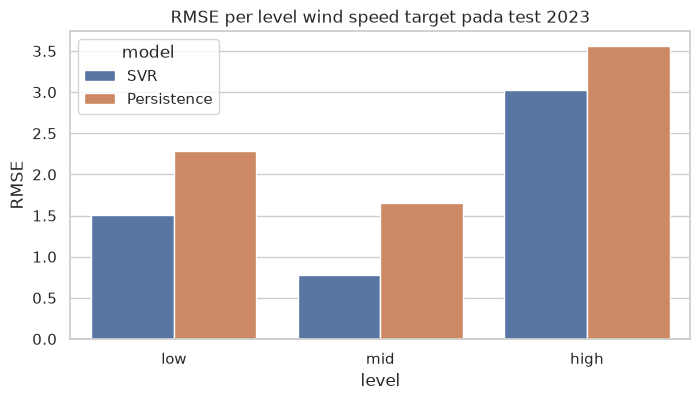

,level,model,RMSE,MAE,n
0,low,SVR,1.5086,1.2375,122
1,mid,SVR,0.7775,0.5842,121
2,high,SVR,3.0240,2.2295,122
3,low,Persistence,2.2903,1.5718,122
4,mid,Persistence,1.6524,1.1303,121
5,high,Persistence,3.5654,2.6964,122


In [30]:
error_by_level = grouped_errors(test_eval, "level", ["low", "mid", "high"])
error_by_level.to_csv(RESULTS_DIR / "error_by_level.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=error_by_level, x="level", y="RMSE", hue="model", ax=ax)
ax.set_title("RMSE per level wind speed target pada test 2023")
fig.savefig(FIG_DIR / "fig_error_by_level.png", dpi=150, bbox_inches="tight")
plt.show()

error_by_level.round(4)

### 7.4 Visualisasi prediksi

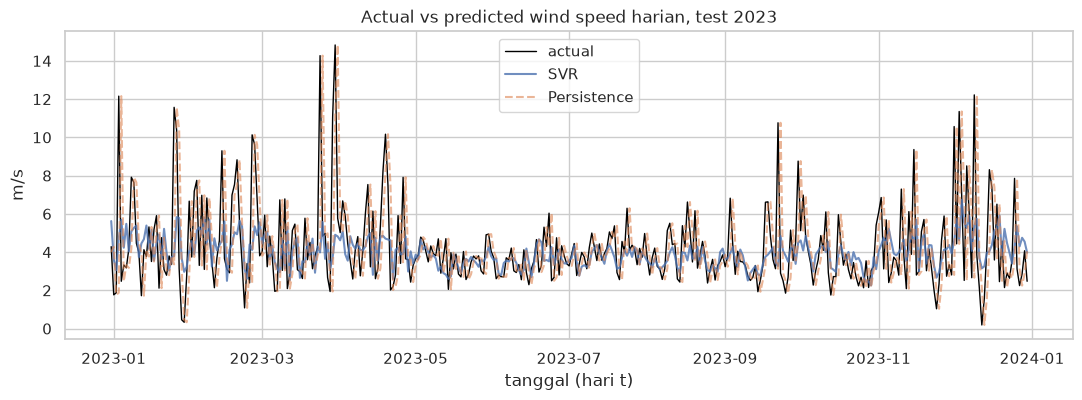

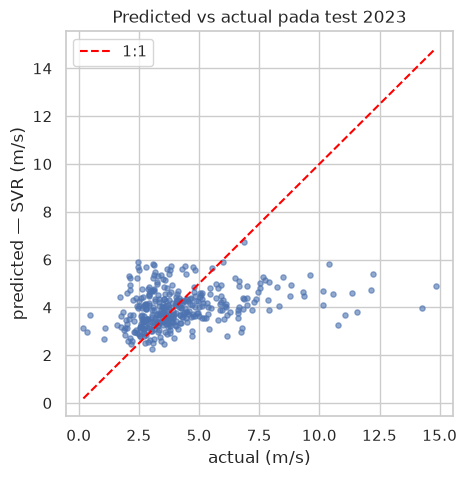

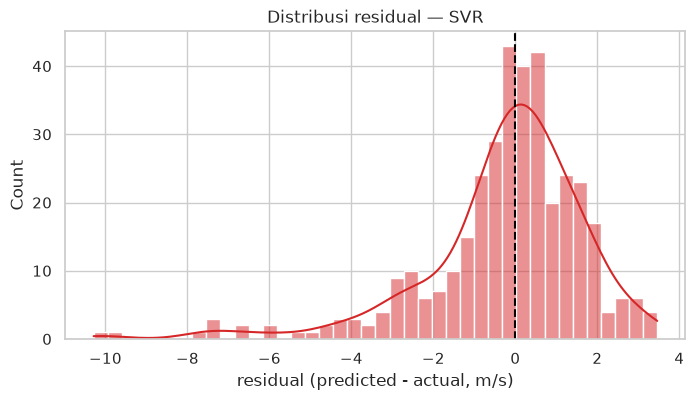

mean residual: -0.2547 | std: 1.9909


In [31]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_eval.index, test_eval["target"], label="actual", color="black", linewidth=1.0)
ax.plot(test_eval.index, test_eval["pred_best"], label=best_model_name, alpha=0.8)
ax.plot(test_eval.index, test_eval["pred_persistence"], label="Persistence", alpha=0.6, linestyle="--")
ax.set_title("Actual vs predicted wind speed harian, test 2023")
ax.set_xlabel("tanggal (hari t)")
ax.set_ylabel("m/s")
ax.legend()
fig.savefig(FIG_DIR / "fig_test_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(test_eval["target"], test_eval["pred_best"], s=14, alpha=0.6)
limits = [test_eval["target"].min(), test_eval["target"].max()]
ax.plot(limits, limits, color="red", linestyle="--", label="1:1")
ax.set_xlabel("actual (m/s)")
ax.set_ylabel(f"predicted — {best_model_name} (m/s)")
ax.set_title("Predicted vs actual pada test 2023")
ax.legend()
fig.savefig(FIG_DIR / "fig_test_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

residuals = test_eval["pred_best"] - test_eval["target"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(residuals, bins=40, kde=True, ax=ax, color="tab:red")
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("residual (predicted - actual, m/s)")
ax.set_title(f"Distribusi residual — {best_model_name}")
fig.savefig(FIG_DIR / "fig_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"mean residual: {residuals.mean():.4f} | std: {residuals.std():.4f}")

### 7.5 Ringkasan

In [32]:
print(metrics_df.sort_values("RMSE").round(4).to_string(index=False))

best_row = metrics_df.loc[metrics_df["model"] == best_model_name].iloc[0]
print(f"\nmodel ML terbaik: {best_model_name}")
print(f"RMSE reduction vs persistence: {best_row['RMSE_reduction_pct']:.2f}%")
print(f"MAE reduction vs persistence: {best_row['MAE_reduction_pct']:.2f}%")
if best_row["RMSE_reduction_pct"] <= 0:
    print("catatan: persistence tetap lebih baik dari model ML terbaik pada test 2023")

print("\ntop-5 fitur (permutation importance):")
print(importance.head(5)[["feature", "permutation_mean", "permutation_std"]].round(4).to_string(index=False))

            model   RMSE    MSE    MAE      R2  RMSE_reduction_pct  MAE_reduction_pct
              SVR 2.0044 4.0177 1.3525  0.0825             23.7341            24.9168
    Random Forest 2.0045 4.0180 1.4171  0.0824             23.7311            21.3300
Linear Regression 2.0271 4.1092 1.4401  0.0616             22.8702            20.0523
        Fine Tree 2.1515 4.6288 1.5357 -0.0570             18.1394            14.7465
      Persistence 2.6282 6.9074 1.8013 -0.5774              0.0000             0.0000

model ML terbaik: SVR
RMSE reduction vs persistence: 23.73%
MAE reduction vs persistence: 24.92%

top-5 fitur (permutation importance):
          feature  permutation_mean  permutation_std
     wind_dir_sin            0.0379           0.0156
     wind_dir_cos            0.0311           0.0139
          doy_cos            0.0304           0.0162
  temperature_50m            0.0258           0.0082
relative_humidity            0.0132           0.0072
